# Calibrating a multispectral camera, advanced: band geometry, NDVI errors, thermal and panchromatic bands

[![Open in Google Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/OpenSkyLab-space/notebooks/blob/main/multispectral_calibration_pro_en.ipynb)

**OpenSkyLab · notebook for the visual** [Calibrating a multispectral camera](https://openskylab.space/edu_viz_multispectral_calibration.html) · [česká verze](multispectral_calibration_pro_cs.ipynb)

The advanced version of the multispectral calibration notebook. The MicaSense Altum-PT camera has seven separate lenses: five multispectral, one panchromatic and one thermal. On a real flight image you find out how the bands shift, rotate and differ in scale against each other and what this does to NDVI, how a calibration error in one band propagates into indices, how surface temperature relates to vegetation, and what sharpening with the panchromatic band can and cannot do.

**Goal:** measure the parallax between bands and from it the camera's distance from the panel, register the bands with an affine transform and compare it with the rig metadata, derive the sensitivity of NDVI to a calibration error, move NDVI onto the thermal grid and compare it with surface temperature, and sharpen the bands with the panchromatic image.

**Data:** two captures (all 7 bands) from a MicaSense Altum-PT camera with DLS 2 from the MicaSense sample data (repository micasense/imageprocessing, MIT licence): IMG_0000 (RP06 panel, 15 August 2022 19:16 UTC) and IMG_0010 (flight 3 minutes later, about 97 m above ground), 48.51° N, 122.42° W. The five multispectral bands have 2064 × 1544 pixels, the panchromatic band 4112 × 3008 and the thermal band 320 × 256. The thermal band is in centikelvin and the camera assumes an emissivity of 1.0 (accuracy ±5 K according to the manufacturer).

**Tasks:** five. Write your answers in the *Your answer* cells below the tasks. Lines marked `# ◀ parameter` are meant to be changed; run the cell again with Shift + Enter.

**Time:** about 60 min. You need a Google account (Colab); nothing is installed on your computer. Run the cells in order from top to bottom.

## 1. Setup and images

We load all seven bands of the flight capture and the five bands of the panel capture. The table shows that every band has its own lens with a slightly different focal length and that the lenses are offset from each other by centimetres (RigTranslations in the metadata, relative to the green band).

In [1]:
import re, io, time, requests
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from scipy import ndimage as ndi
from matplotlib.path import Path

In [2]:
BASE = "https://media.githubusercontent.com/media/micasense/imageprocessing/master/data/ALTUM-PT/"
def fetch(name, tries=5):
    for i in range(tries):
        try:
            r = requests.get(BASE + name, timeout=120); r.raise_for_status(); return r.content
        except requests.RequestException as e:
            print(name, type(e).__name__, "– retrying"); time.sleep(3 * (i + 1))
    raise RuntimeError("The images could not be downloaded.")

def xmp_reader(raw):
    x = raw[raw.find(b"<x:xmpmeta"): raw.find(b"</x:xmpmeta>")].decode()
    def get(tag):
        m = re.search(rf"<{tag}>(.*?)</{tag}>", x, re.S)
        if not m: return None
        v = m.group(1)
        if "<rdf:li>" in v:
            return [float(s) for li in re.findall(r"<rdf:li>\s*([^<]+?)\s*</rdf:li>", v) for s in li.split(",")]
        if "," in v: return [float(s) for s in v.split(",")]
        try: return float(v)
        except ValueError: return v.strip()
    return get

def load(name):
    """Loads one band: the DN array and a dict of metadata (radiometry, DLS, lens and rig geometry)."""
    raw = fetch(name); im = Image.open(io.BytesIO(raw)); ex = im.getexif(); sub = ex.get_ifd(0x8769); gps = ex.get_ifd(0x8825); g = xmp_reader(raw)
    m = dict(band=g("Camera:BandName"), wl=g("Camera:CentralWavelength"), exposure=float(sub.get(33434, 1.0)), gain=sub.get(34867, 100) / 100,
             black=float(np.mean(ex[50714])) if 50714 in ex else 0.0, bits=ex[258], cal=g("MicaSense:RadiometricCalibration"),
             vig_c=g("Camera:VignettingCenter"), vig_p=g("Camera:VignettingPolynomial"),
             vig_2d=g("Camera:VignettingPolynomial2D"), vig_e=g("Camera:VignettingPolynomial2DName"),
             albedo=g("Camera:Albedo"), area=g("Camera:ReflectArea"), time=ex[306], alt=float(gps[6]),
             E_h=g("DLS:HorizontalIrradiance"), sun_el=g("DLS:SolarElevation"),
             f=g("Camera:PerspectiveFocalLength"), pp=g("Camera:PrincipalPoint"), pitch=1 / float(sub[41486]),   # mm, mm, mm
             rig_t=g("Camera:RigTranslations"), rig_r=g("Camera:RigRelatives"))
    if m["E_h"] is not None: m["E_h"] *= 0.01    # µW/cm²/nm → W/m²/nm
    return np.array(im).astype(np.float32), m

def vig_factor(m, shape):
    y, x = np.indices(shape)
    if m["vig_c"] is not None:
        return 1 / np.polyval(list(m["vig_p"])[::-1] + [1.0], np.hypot(x - m["vig_c"][0], y - m["vig_c"][1]))
    xv, yv = x / shape[1], y / shape[0]
    return 1 / sum(c * xv ** m["vig_e"][2 * i] * yv ** m["vig_e"][2 * i + 1] for i, c in enumerate(m["vig_2d"]))

def radiance(dn, m):
    """Radiance (W/m²/sr/nm) with the MicaSense model as in the basic version."""
    y, x = np.indices(dn.shape)
    a1, a2, a3 = m["cal"]
    R = 1 / (1 + a2 * y / m["exposure"] - a3 * y)
    return (np.clip(vig_factor(m, dn.shape) * R * (dn - m["black"]), 0, None) / (m["gain"] * m["exposure"]) * a1 / 2 ** m["bits"]).astype(np.float32)

PANEL = {b: load(f"IMG_0000_{b}.tif") for b in range(1, 6)}
FLIGHT = {b: load(f"IMG_0010_{b}.tif") for b in range(1, 8)}     # 6 panchromatic, 7 thermal
tab = pd.DataFrame({b: {"band": m["band"], "λ (nm)": m["wl"], "pixels": f"{dn.shape[1]} × {dn.shape[0]}", "f (mm)": m["f"],
                        "pixel (µm)": 1000 * m["pitch"], "offset from band 2, x y z (mm)": m["rig_t"]}
                    for b, (dn, m) in FLIGHT.items()}).T
print(tab.to_string())
print("panel:", PANEL[1][1]["time"], f"GPS {PANEL[1][1]['alt']:.1f} m a.s.l.", " flight:", FLIGHT[1][1]["time"], f"GPS {FLIGHT[1][1]['alt']:.1f} m a.s.l.")

       band   λ (nm)       pixels     f (mm) pixel (µm)     offset from band 2, x y z (mm)
1      Blue    475.0  2064 × 1544     7.8828       3.45     [-49.01269, -0.2451, 0.718963]
2     Green    560.0  2064 × 1544   7.862345       3.45                    [0.0, 0.0, 0.0]
3       Red    668.0  2064 × 1544   7.892093       3.45   [-12.10394, 24.29775, -0.620508]
4       NIR    842.0  2064 × 1544   7.867275       3.45  [-24.59074, -0.194283, -0.968696]
5  Red edge    717.0  2064 × 1544   7.891018       3.45   [-36.54579, 24.43246, -0.660754]
6   Panchro    634.5  4112 × 3008  16.577383       3.45    [-37.06401, -47.09952, 4.89484]
7      LWIR  11000.0    320 × 256   4.444976       12.0    [-8.32026, -45.82793, -4.55625]
panel: 2022:08:15 19:16:11 GPS 12.0 m a.s.l.  flight: 2022:08:15 19:18:54 GPS 108.0 m a.s.l.


## 2. Parallax between bands

Two lenses a distance T apart see the same point at a distance H shifted by Δ = T · f / (H · p) pixels, where f is the focal length and p the sensor pixel size. From 100 m this is about one pixel, from a metre above the ground over a hundred. Part of the shift does not depend on the distance (the lenses are not exactly parallel), so we compare the shift in the panel image and in the flight image: the difference is almost pure parallax of the panel image.

          Tx (mm)  Ty (mm)  panel dx  panel dy  flight dx  flight dy     Δdx    Δdy  flight parallax (px)
Blue       -49.01    -0.25    113.66     -6.05      -8.19      -5.92  121.85  -0.13                  1.15
Green        0.00     0.00     -0.00     -0.00      -0.00      -0.00    0.00  -0.00                  0.00
Red        -12.10    24.30     33.93    -59.18       3.69       2.76   30.24 -61.94                  0.64
NIR        -24.59    -0.19     58.62      7.75      -2.69       7.12   61.30   0.62                  0.58
Red edge   -36.55    24.43     97.37    -63.40       6.04      -2.02   91.33 -61.38                  1.03
parallax in the panel image 2.50 px per mm → the camera was 0.91 m above the panel
flight height above ground ≈ 97 m (GPS 108.0 − 12.0 m + 0.91 m)


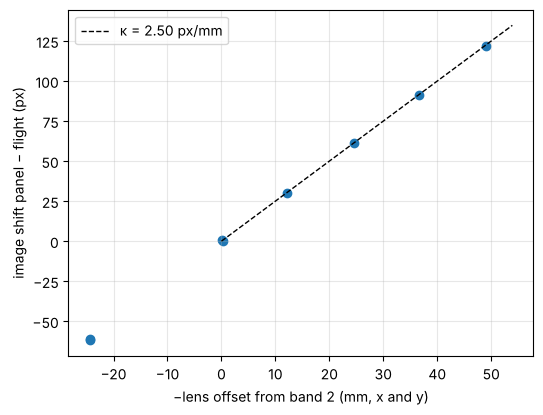

In [3]:
REF = 2                       # reference band (green); the lens offsets in the metadata are relative to it

def shift_sub(a, c):
    """Shift (dy, dx) by which c must be moved to match a: phase correlation of gradients with subpixel refinement."""
    g = lambda z: np.hypot(*np.gradient(ndi.gaussian_filter(z, 1.5)))
    w = np.outer(np.hanning(a.shape[0]), np.hanning(a.shape[1]))
    F = np.fft.fft2(g(a) * w) * np.conj(np.fft.fft2(g(c) * w)); cc = np.fft.ifft2(F / (np.abs(F) + 1e-12)).real
    i, j = np.unravel_index(cc.argmax(), cc.shape); H, W = cc.shape
    def par(m, z, p): d = m - 2 * z + p; return 0.5 * (m - p) / d if d else 0.0
    dy = i + par(cc[i - 1, j], cc[i, j], cc[(i + 1) % H, j]); dx = j + par(cc[i, j - 1], cc[i, j], cc[i, (j + 1) % W])
    return np.array([dy - H if dy > H / 2 else dy, dx - W if dx > W / 2 else dx]), cc.max() / cc.std()

rows = {}
for b in range(1, 6):
    sp, _ = shift_sub(PANEL[REF][0], PANEL[b][0]); sf, _ = shift_sub(FLIGHT[REF][0], FLIGHT[b][0])
    tx, ty = FLIGHT[b][1]["rig_t"][:2]
    rows[FLIGHT[b][1]["band"]] = {"Tx (mm)": tx, "Ty (mm)": ty, "panel dx": sp[1], "panel dy": sp[0],
                                  "flight dx": sf[1], "flight dy": sf[0], "Δdx": sp[1] - sf[1], "Δdy": sp[0] - sf[0]}
par_tab = pd.DataFrame(rows).T
o = par_tab.drop(FLIGHT[REF][1]["band"])
T = np.r_[o["Tx (mm)"], o["Ty (mm)"]]; D = np.r_[o["Δdx"], o["Δdy"]]
kappa = -(T @ D) / (T @ T)                                    # px per mm of lens offset (panel minus flight)
f, p = FLIGHT[REF][1]["f"], FLIGHT[REF][1]["pitch"]
H_panel = f / (p * kappa) / 1000                              # m; the flight parallax (~1 px) neglected
H_flight = FLIGHT[1][1]["alt"] - PANEL[1][1]["alt"] + H_panel # flight height above ground from the GPS height difference
par_tab["flight parallax (px)"] = np.hypot(par_tab["Tx (mm)"], par_tab["Ty (mm)"]) * f / (H_flight * 1000 * p)
print(par_tab.round(2).to_string())
print(f"parallax in the panel image {kappa:.2f} px per mm → the camera was {H_panel:.2f} m above the panel")
print(f"flight height above ground ≈ {H_flight:.0f} m (GPS {FLIGHT[1][1]['alt']:.1f} − {PANEL[1][1]['alt']:.1f} m + {H_panel:.2f} m)")
fig, ax = plt.subplots(figsize=(6, 4.5))
ax.scatter(-T, D, c="C0"); tt = np.linspace(0, 1.1 * np.abs(T).max(), 2)
ax.plot(tt, kappa * tt, "k--", lw=1, label=f"κ = {kappa:.2f} px/mm")
ax.set_xlabel("−lens offset from band 2 (mm, x and y)"); ax.set_ylabel("image shift panel − flight (px)")
ax.legend(); ax.grid(alpha=0.3); plt.show()

> **✏️ Task 1.** Why does the band shift in the panel image differ from the shift in the flight image by tens of pixels, although it is the same camera? From what distance was the panel photographed, and what flight height above ground does this give? Compute the parallax of the blue band against the green one for a flight at 30 m and for a flight at 40 m over a forest with 20 m tall crowns (for the crowns and for the ground). Why is one shift for the whole image then not enough to register the bands?

*Your answer:* 

## 3. Scale and rotation of the bands

We measure the shift separately in each 256 × 256 pixel tile and fit it with an affine transform d = t + A · (x, y): t is the shift at the centre, the matrix A gives the difference in scale and the rotation. The scale difference should match the ratio of the focal lengths, the rotation the third RigRelatives angle (in degrees in the metadata).

          shift t (px) scale (%) from focal lengths (%) rotation (°) RigRelatives, third angle (°) spread of the shift over the image (px) residual after affine (px, median)
Blue      [-8.5, -5.6]    -0.291                 -0.259        0.095                         0.097                                   7.597                              0.233
Red         [3.2, 2.6]    -0.362                 -0.377       -0.045                        -0.047                                   7.802                              0.455
NIR        [-2.5, 7.5]     0.009                 -0.063        0.122                         0.121                                   5.040                              0.393
Red edge   [5.4, -1.6]    -0.315                 -0.363        0.032                         0.034                                   6.369                              0.415


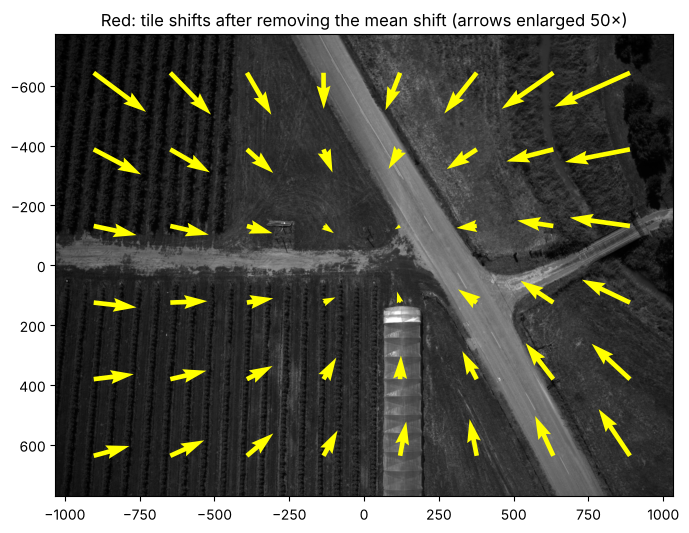

In [4]:
TILE = 256                    # ◀ parameter: tile size (px)
BAND = 3                      # ◀ parameter: band for the shift map (1 blue, 3 red, 4 NIR, 5 red edge)
ref = FLIGHT[REF][0]; Hh, Ww = ref.shape; cy0, cx0 = (Hh - 1) / 2, (Ww - 1) / 2

def tile_shifts(img):
    out = []
    for y0 in range(0, Hh - TILE + 1, TILE):
        for x0 in range(0, Ww - TILE + 1, TILE):
            s, q = shift_sub(ref[y0:y0 + TILE, x0:x0 + TILE], img[y0:y0 + TILE, x0:x0 + TILE])
            out.append((x0 + TILE / 2 - cx0, y0 + TILE / 2 - cy0, s[1], s[0], q))
    return np.array(out)

def fit_affine(r):
    """Shift d = t + A · (x, y) by least squares (coordinates from the image centre)."""
    X = np.c_[np.ones(len(r)), r[:, 0], r[:, 1]]
    cx = np.linalg.lstsq(X, r[:, 2], rcond=None)[0]; cy = np.linalg.lstsq(X, r[:, 3], rcond=None)[0]
    res = np.hypot(r[:, 2] - X @ cx, r[:, 3] - X @ cy)
    return np.array([cx[0], cy[0]]), np.array([[cx[1], cx[2]], [cy[1], cy[2]]]), res

AFF, rows = {}, {}
for b in range(1, 6):
    if b == REF: AFF[b] = (np.zeros(2), np.zeros((2, 2))); continue
    r = tile_shifts(FLIGHT[b][0]); t, A, res = fit_affine(r); AFF[b] = (t, A)
    m = FLIGHT[b][1]
    rows[m["band"]] = {"shift t (px)": np.round(t, 1), "scale (%)": 100 * (A[0, 0] + A[1, 1]) / 2,
                       "from focal lengths (%)": 100 * (FLIGHT[REF][1]["f"] / m["f"] - 1),
                       "rotation (°)": np.degrees((A[1, 0] - A[0, 1]) / 2), "RigRelatives, third angle (°)": m["rig_r"][2],
                       "spread of the shift over the image (px)": np.ptp(np.hypot(r[:, 2], r[:, 3])),
                       "residual after affine (px, median)": np.median(res)}
    if b == BAND: r_show = r
print(pd.DataFrame(rows).T.to_string(float_format=lambda v: f"{v:.3f}"))
fig, ax = plt.subplots(figsize=(8, 6))
ax.imshow(ref, cmap="gray", extent=(-cx0, Ww - cx0, Hh - cy0, -cy0))
t = AFF[BAND][0]
ax.quiver(r_show[:, 0], r_show[:, 1], r_show[:, 2] - t[0], r_show[:, 3] - t[1], color="yellow", angles="xy", scale_units="xy", scale=0.02)
ax.set_title(f"{FLIGHT[BAND][1]['band']}: tile shifts after removing the mean shift (arrows enlarged 50×)")
plt.show()

share of pixels with |ΔNDVI| > 0.05:
  centre of the image (one third): 18.1 %
  edge of the image (outer fifth): 42.3 %
  edges (steep NDVI gradient): 66.7 %
  whole image: 36.3 %


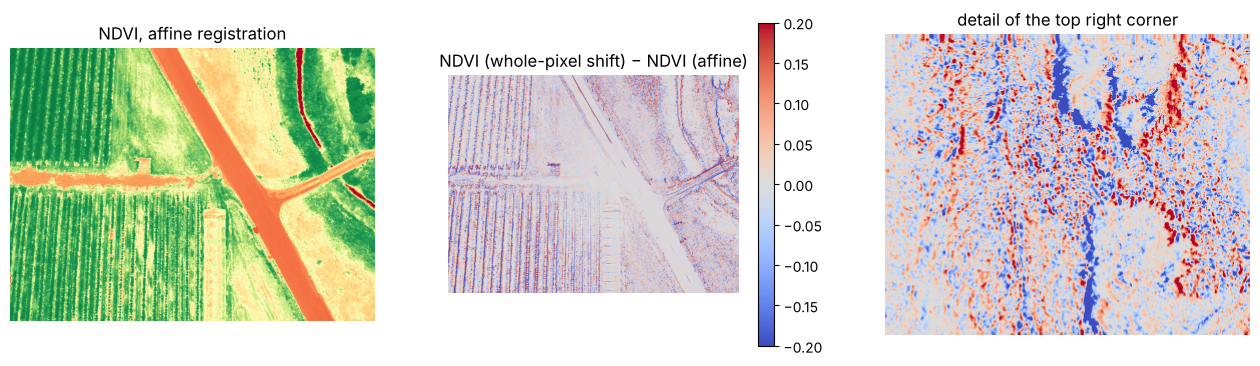

In [5]:
def warp(img, t, A):
    """Moves a band onto the reference grid: out(p) = in(p − t − A·p), coordinates from the centre."""
    Myx = np.array([[A[1, 1], A[1, 0]], [A[0, 1], A[0, 0]]])       # rows (y, x)
    M = np.eye(2) - Myx; c = np.array([cy0, cx0])
    return ndi.affine_transform(img, M, offset=c - M @ c - t[::-1], order=1, mode="nearest")

L_fl = {b: radiance(*FLIGHT[b]) for b in range(1, 6)}
L_tr = {b: ndi.shift(L_fl[b], np.round(AFF[b][0][::-1]), order=0, mode="nearest") for b in L_fl}   # only a whole-pixel shift as in the basic version
L_af = {b: warp(L_fl[b], *AFF[b]) for b in L_fl}
k = {b: PANEL[b][1]["albedo"] / radiance(*PANEL[b])[Path(np.array(PANEL[b][1]["area"]).reshape(-1, 2)).contains_points(
         np.c_[np.indices(PANEL[b][0].shape)[1].ravel(), np.indices(PANEL[b][0].shape)[0].ravel()]).reshape(PANEL[b][0].shape)].mean() for b in L_fl}
def refl(L): return {b: k[b] * L[b] * PANEL[b][1]["E_h"] / FLIGHT[b][1]["E_h"] for b in L}   # panel + DLS
ndvi = lambda R: (R[4] - R[3]) / (R[4] + R[3] + 1e-9)
RHO_tr, RHO_af = refl(L_tr), refl(L_af)
N_tr, N_af = ndvi(RHO_tr), ndvi(RHO_af)
dN = N_tr - N_af
yy, xx = np.indices(dN.shape); edge = np.maximum(np.abs(xx - cx0) / cx0, np.abs(yy - cy0) / cy0)
grad = np.hypot(*np.gradient(ndi.gaussian_filter(N_af, 1)))
print("share of pixels with |ΔNDVI| > 0.05:")
for name, msk in [("centre of the image (one third)", edge < 1 / 3), ("edge of the image (outer fifth)", edge > 0.8),
                  ("edges (steep NDVI gradient)", grad > np.percentile(grad, 90)), ("whole image", edge >= 0)]:
    print(f"  {name}: {100 * np.mean(np.abs(dN[msk]) > 0.05):.1f} %")
fig, ax = plt.subplots(1, 3, figsize=(16, 4.2))
ax[0].imshow(N_af, cmap="RdYlGn", vmin=-0.2, vmax=1); ax[0].set_title("NDVI, affine registration")
im = ax[1].imshow(dN, cmap="coolwarm", vmin=-0.2, vmax=0.2); ax[1].set_title("NDVI (whole-pixel shift) − NDVI (affine)"); plt.colorbar(im, ax=ax[1])
r, c = slice(0, 300), slice(1700, 2064)
ax[2].imshow(dN[r, c], cmap="coolwarm", vmin=-0.2, vmax=0.2); ax[2].set_title("detail of the top right corner")
for a in ax: a.axis("off")
plt.show()

> **✏️ Task 2.** Why does the band shift change across the image (look at the arrows for the red band and then for NIR)? Does the scale agree with the ratio of the focal lengths and the rotation with RigRelatives? By how many pixels does the real shift in the corner of the image differ from the shift at the centre? Where in the image and on which objects does NDVI from a whole-pixel shift (as in the basic version) differ most from the affine registration, and why there?

*Your answer:* 

## 4. How a calibration error propagates into NDVI

When NIR has a relative error e_NIR and the red band e_Red, NDVI changes by approximately ΔNDVI ≈ (1 − NDVI²) / 2 · (e_NIR − e_Red). A common error of both bands cancels out. We compare the formula with the computation on the image and look at what calibration from the DLS alone, without the panel, does to the indices.

            ρ Red  ρ NIR   NDVI  ΔNDVI with the error  ΔNDVI from the formula  ΔNDVI DLS only   NDRE  ΔNDRE DLS only
road        0.170  0.192  0.055                 0.024                   0.024           0.019  0.041           0.020
dry meadow  0.134  0.251  0.301                 0.022                   0.022           0.018  0.192           0.019
orchard     0.016  0.308  0.897                 0.005                   0.005           0.004  0.452           0.016
ratio of reflectance DLS only / panel + DLS by band: {'Blue': 0.642, 'Green': 0.785, 'Red': 0.908, 'NIR': 0.944, 'Red edge': 0.907}


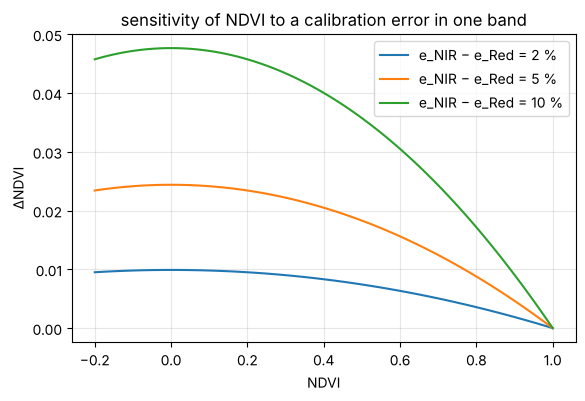

In [6]:
REGIONS = {"road": (slice(1140, 1260), slice(1570, 1650)), "dry meadow": (slice(100, 500), slice(1120, 1500)), "orchard": (slice(20, 640), slice(20, 560))}   # ◀ parameter: regions (rows, columns)
ERR_RED, ERR_NIR = 0.00, 0.05   # ◀ parameter: relative calibration error of the red and NIR band (0.05 = +5 %)

R_ok = RHO_af
R_err = dict(R_ok); R_err[3] = R_ok[3] * (1 + ERR_RED); R_err[4] = R_ok[4] * (1 + ERR_NIR)
R_dls = {b: np.pi * L_af[b] / FLIGHT[b][1]["E_h"] for b in L_af}     # DLS only
ndre = lambda R: (R[4] - R[5]) / (R[4] + R[5] + 1e-9)
rows = {}
for reg, (r, c) in REGIONS.items():
    n0 = np.median(ndvi(R_ok)[r, c])
    rows[reg] = {"ρ Red": np.median(R_ok[3][r, c]), "ρ NIR": np.median(R_ok[4][r, c]), "NDVI": n0,
                 "ΔNDVI with the error": np.median(ndvi(R_err)[r, c]) - n0,
                 "ΔNDVI from the formula": (1 - n0 ** 2) / 2 * (np.log1p(ERR_NIR) - np.log1p(ERR_RED)),
                 "ΔNDVI DLS only": np.median(ndvi(R_dls)[r, c]) - n0,
                 "NDRE": np.median(ndre(R_ok)[r, c]), "ΔNDRE DLS only": np.median(ndre(R_dls)[r, c]) - np.median(ndre(R_ok)[r, c])}
print(pd.DataFrame(rows).T.round(3).to_string())
ratio = {FLIGHT[b][1]["band"]: np.median(R_dls[b] / R_ok[b]) for b in L_af}
print("ratio of reflectance DLS only / panel + DLS by band:", {b: round(float(v), 3) for b, v in ratio.items()})
nn = np.linspace(-0.2, 1, 100)
fig, ax = plt.subplots(figsize=(6.5, 4))
for e in (0.02, 0.05, 0.10):
    ax.plot(nn, (1 - nn ** 2) / 2 * np.log1p(e), label=f"e_NIR − e_Red = {100 * e:.0f} %")
ax.set_xlabel("NDVI"); ax.set_ylabel("ΔNDVI"); ax.legend(); ax.grid(alpha=0.3); ax.set_title("sensitivity of NDVI to a calibration error in one band")
plt.show()

> **✏️ Task 3.** Set ERR_NIR = 0.05 and ERR_RED = 0: why does NDVI of the road and the meadow shift more than NDVI of the orchard? Check the formula for ERR_RED = 0.05 and for ERR_RED = ERR_NIR. Calibration from the DLS alone gives reflectance in the individual bands that differs by several to tens of percent (the ratio was printed), yet NDVI changes only by hundredths. Why? For which tasks is the DLS without a panel enough, and for which is it not?

*Your answer:* 

## 5. The thermal band and vegetation

The thermal band stores temperature in centikelvin, computed with an emissivity of 1.0. A real surface has a lower emissivity, and part of the radiation the camera sees is reflected sky. In the grey-body approximation σT_b⁴ = ε σT⁴ + (1 − ε) σT_sky⁴. The thermal camera has a coarser pixel and a different focal length, so we average NDVI to the size of a thermal pixel, convert via the principal points of the lenses and find the remaining shift so that the correlation of NDVI and temperature is strongest.

ground sample distance (GSD) at 97 m: {'Green': '4.3 cm', 'Panchro': '2.0 cm', 'LWIR': '26.2 cm'}


1 thermal pixel = 6.15 MS pixels; refining shift (13.0, -25.0) MS px; correlation of NDVI and temperature r = -0.62
            thermal pixels  camera T (°C)  T for ε = 0.95  NDVI (on the thermal grid)
road                 260.0          38.40           40.95                        0.05
dry meadow          3965.0          39.49           42.07                        0.31
orchard             6666.0          29.28           31.57                        0.88
for NDVI > 0.3: temperature drops by 1.36 °C per 0.1 NDVI


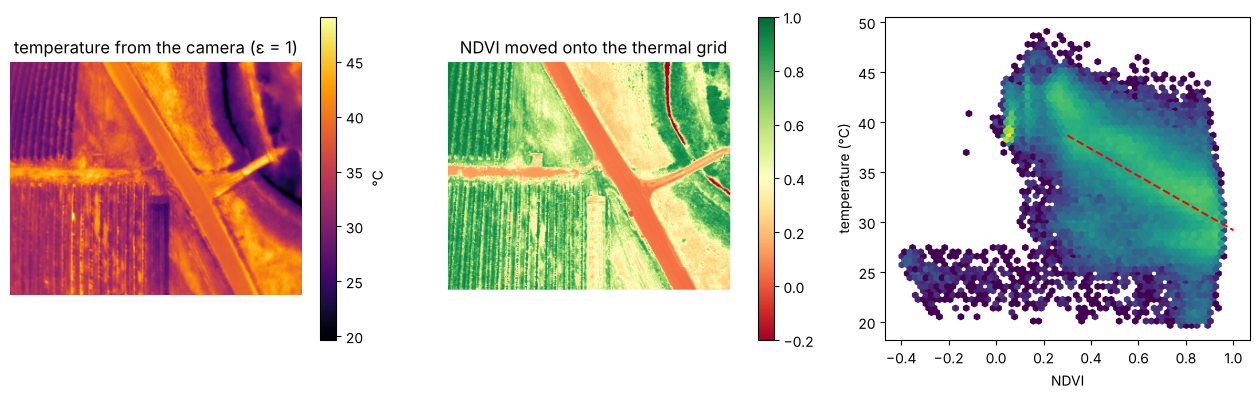

In [7]:
EPS = 0.95                    # ◀ parameter: surface emissivity for the correction (the camera assumes 1.0)
T_SKY = -30.0                 # ◀ parameter: sky brightness temperature (°C), an assumption for a clear sky
dn_t, mt = FLIGHT[7]
Tb = dn_t / 100 - 273.15                                          # centikelvin → °C
ms, mp = FLIGHT[REF][1], FLIGHT[6][1]
gsd = {FLIGHT[b][1]["band"]: 100 * H_flight * FLIGHT[b][1]["pitch"] / FLIGHT[b][1]["f"] for b in (REF, 6, 7)}
print(f"ground sample distance (GSD) at {H_flight:.0f} m:", {b: f"{v:.1f} cm" for b, v in gsd.items()})

s_t = (ms["f"] / ms["pitch"]) / (mt["f"] / mt["pitch"])          # how many MS pixels fall on one thermal pixel
pp_ms = np.array(ms["pp"]) / ms["pitch"]; pp_t = np.array(mt["pp"]) / mt["pitch"]   # principal point in pixels (x, y)
N_box = ndi.uniform_filter(N_af, size=int(round(s_t)))
yt, xt = np.indices(Tb.shape)
def ndvi_on_thermal(d):
    xm = pp_ms[0] + (xt + 0.5 - pp_t[0]) * s_t - 0.5 + d[1]; ym = pp_ms[1] + (yt + 0.5 - pp_t[1]) * s_t - 0.5 + d[0]
    return ndi.map_coordinates(N_box, [ym, xm], order=1, cval=np.nan), ym, xm
def score(d):
    n, _, _ = ndvi_on_thermal(d); ok = np.isfinite(n) & (n != 0)
    return np.corrcoef(n[ok], Tb[ok])[0, 1]
best = min(((dy, dx) for dy in range(-80, 81, 4) for dx in range(-80, 81, 4)), key=score)        # coarse search for the shift
best = min(((best[0] + dy, best[1] + dx) for dy in np.arange(-4, 4.5, 0.5) for dx in np.arange(-4, 4.5, 0.5)), key=score)
N_t, ym, xm = ndvi_on_thermal(best)
print(f"1 thermal pixel = {s_t:.2f} MS pixels; refining shift ({best[0]:.1f}, {best[1]:.1f}) MS px; correlation of NDVI and temperature r = {score(best):.2f}")

def t_corr(tb, eps, t_sky):
    """Emissivity correction in the grey-body approximation: σT_b⁴ = ε σT⁴ + (1 − ε) σT_sky⁴."""
    K = 273.15
    return (((tb + K) ** 4 - (1 - eps) * (t_sky + K) ** 4) / eps) ** 0.25 - K
rows = {}
for reg, (r, c) in REGIONS.items():
    inside = (ym >= r.start) & (ym < r.stop) & (xm >= c.start) & (xm < c.stop)
    tb = np.median(Tb[inside])
    rows[reg] = {"thermal pixels": inside.sum(), "camera T (°C)": tb, f"T for ε = {EPS}": t_corr(tb, EPS, T_SKY),
                 "NDVI (on the thermal grid)": np.median(N_t[inside])}
print(pd.DataFrame(rows).T.round(2).to_string())
ok = np.isfinite(N_t)
veg = ok & (N_t > 0.3)
a, b0 = np.polyfit(N_t[veg], Tb[veg], 1)
print(f"for NDVI > 0.3: temperature drops by {-a / 10:.2f} °C per 0.1 NDVI")
fig, ax = plt.subplots(1, 3, figsize=(16, 4.2))
im = ax[0].imshow(Tb, cmap="inferno"); plt.colorbar(im, ax=ax[0], label="°C"); ax[0].set_title("temperature from the camera (ε = 1)")
im = ax[1].imshow(N_t, cmap="RdYlGn", vmin=-0.2, vmax=1); plt.colorbar(im, ax=ax[1]); ax[1].set_title("NDVI moved onto the thermal grid")
ax[2].hexbin(N_t[ok], Tb[ok], gridsize=60, bins="log", cmap="viridis"); ax[2].plot(nn := np.linspace(0.3, 1, 2), a * nn + b0, "r--")
ax[2].set_xlabel("NDVI"); ax[2].set_ylabel("temperature (°C)")
for x in ax[:2]: x.axis("off")
plt.show()

> **✏️ Task 4.** How large is a thermal pixel on the ground, and how many multispectral pixels fall into it? How warm are the road, the dry meadow and the orchard, and what explains that the orchard is so much cooler? Find the points with NDVI below zero and low temperature in the plot and on the maps: what are they? Set EPS to 0.97 (vegetation) and 0.92 (dry soil) and T_SKY to −10 °C (cloudy): by how much does the temperature change, and is that more or less than the accuracy of the camera?

*Your answer:* 

## 6. Sharpening with the panchromatic band

The panchromatic band captures a wide range of wavelengths (the centre and width are in the table in step 1) with a pixel half the size. The HPM method (high-pass modulation) multiplies each resampled band by the ratio pan / pan blurred to the MS resolution. We first register pan to the mean of bands 1–4 in the same way as in step 3.

1 MS pixel = 2.11 pan pixels; pan against MS: shift [ -0.7 -17.2] MS px, scale +0.13 %, rotation of pan against MS -0.30° (RigRelatives -0.32°)
correlation of pan and the mean of bands 1–4: without correction 0.514, with correction 0.697; residual after affine 1.08 px


largest difference between sharpened and resampled NDVI: 1.8e-07
mean Red reflectance before and after sharpening: 0.1242 and 0.1241
share of fine detail: Red resampled 0.064, Red sharpened 0.101, pan 0.153


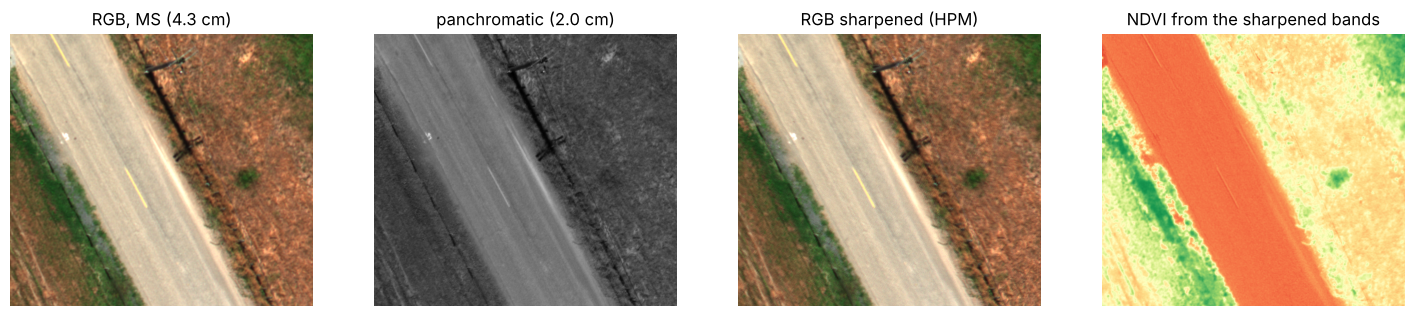

In [8]:
CROP = (slice(1000, 1400), slice(1400, 1850))    # ◀ parameter: crop in MS pixels (rows, columns)
dn_p, mp = FLIGHT[6]
P = radiance(dn_p, mp)
s_p = (mp["f"] / mp["pitch"]) / (ms["f"] / ms["pitch"])          # how many pan pixels fall on one MS pixel
pp_p = np.array(mp["pp"]) / mp["pitch"]
P_box = ndi.uniform_filter(P, size=int(round(s_p)))
cen = np.array([cx0, cy0])

def ms_to_pan(x, y, t, A):
    """Pan coordinates (x, y) for an MS pixel (x, y): via the principal points and the scale, corrected by the shift t and the affine matrix A."""
    xq = x + t[0] + A[0, 0] * (x - cen[0]) + A[0, 1] * (y - cen[1]); yq = y + t[1] + A[1, 0] * (x - cen[0]) + A[1, 1] * (y - cen[1])
    return pp_p[0] + (xq + 0.5 - pp_ms[0]) * s_p - 0.5, pp_p[1] + (yq + 0.5 - pp_ms[1]) * s_p - 0.5

intensity = sum(L_af[b] for b in (1, 2, 3, 4)) / 4
yy, xx = np.indices(intensity.shape)
def pan_on_ms(t, A):
    xp, yp = ms_to_pan(xx, yy, t, A)
    return ndi.map_coordinates(P_box, [yp, xp], order=1, cval=0)
P0 = pan_on_ms(np.zeros(2), np.zeros((2, 2)))
ref, ref_save = P0, ref                                        # tiles: pan (conversion only) against the mean of bands 1–4
r_pan = tile_shifts(intensity); ref = ref_save
t_p, A_p, res_p = fit_affine(r_pan)
P_ms = pan_on_ms(t_p, A_p)
print(f"1 MS pixel = {s_p:.2f} pan pixels; pan against MS: shift {np.round(t_p, 1)} MS px, scale {100 * (A_p[0, 0] + A_p[1, 1]) / 2:+.2f} %, rotation of pan against MS {-np.degrees((A_p[1, 0] - A_p[0, 1]) / 2):+.2f}° (RigRelatives {mp['rig_r'][2]:+.2f}°)")
print(f"correlation of pan and the mean of bands 1–4: without correction {np.corrcoef(P0.ravel(), intensity.ravel())[0, 1]:.3f}, with correction {np.corrcoef(P_ms.ravel(), intensity.ravel())[0, 1]:.3f}; residual after affine {np.median(res_p):.2f} px")

# the crop on the pan grid: for each pan pixel we find the MS coordinates (inverse mapping)
r, c = CROP
x0p, y0p = ms_to_pan(c.start, r.start, t_p, A_p); x1p, y1p = ms_to_pan(c.stop, r.stop, t_p, A_p)
yP, xP = np.mgrid[int(y0p):int(y1p), int(x0p):int(x1p)].astype(float)
qx = (xP + 0.5 - pp_p[0]) / s_p + pp_ms[0] - 0.5 - t_p[0] - cen[0]; qy = (yP + 0.5 - pp_p[1]) / s_p + pp_ms[1] - 0.5 - t_p[1] - cen[1]
Ai = np.linalg.inv(np.eye(2) + A_p)
xM = cen[0] + Ai[0, 0] * qx + Ai[0, 1] * qy; yM = cen[1] + Ai[1, 0] * qx + Ai[1, 1] * qy
pan_c = ndi.map_coordinates(P, [yP, xP], order=1)
up = {b: ndi.map_coordinates(RHO_af[b], [yM, xM], order=1) for b in (1, 2, 3, 4)}           # MS resampled onto the pan grid
pan_low = ndi.map_coordinates(P_ms, [yM, xM], order=1)                                      # pan blurred to the MS resolution
sharp = {b: up[b] * pan_c / pan_low for b in up}                                            # HPM: MS × pan / pan_low
N_up, N_sh = ndvi(up), ndvi(sharp)
print(f"largest difference between sharpened and resampled NDVI: {np.nanmax(np.abs(N_sh - N_up)):.1e}")
print(f"mean Red reflectance before and after sharpening: {up[3].mean():.4f} and {sharp[3].mean():.4f}")
hf = lambda a: np.std(a - ndi.gaussian_filter(a, 2)) / np.std(a)      # share of fine detail (up to ~2 pan pixels)
print(f"share of fine detail: Red resampled {hf(up[3]):.3f}, Red sharpened {hf(sharp[3]):.3f}, pan {hf(pan_c):.3f}")
rgb = lambda D: np.clip(np.dstack([D[3], D[2], D[1]]) / np.percentile(np.dstack([up[3], up[2], up[1]]), 99.5), 0, 1)
fig, ax = plt.subplots(1, 4, figsize=(18, 4.6))
ax[0].imshow(rgb(up)); ax[0].set_title(f"RGB, MS ({gsd[ms['band']]:.1f} cm)")
ax[1].imshow(pan_c, cmap="gray"); ax[1].set_title(f"panchromatic ({gsd[mp['band']]:.1f} cm)")
ax[2].imshow(rgb(sharp)); ax[2].set_title("RGB sharpened (HPM)")
ax[3].imshow(N_sh, cmap="RdYlGn", vmin=-0.2, vmax=1); ax[3].set_title("NDVI from the sharpened bands")
for a in ax: a.axis("off")
plt.show()

> **✏️ Task 5.** How many times finer is the panchromatic pixel, and by how much did the share of fine detail in the red band increase? Why is NDVI from the sharpened bands the same as from the unsharpened ones (the difference is at the level of rounding)? Why does sharpening not change the mean reflectance? Pan also covers part of NIR: is the sharpened red band as trustworthy for vegetation as the sharpened green one? Consider how vegetation looks in pan and how in the red band.

*Your answer:* 

> **✏️ Extension (optional).** From the GSD table compute at what height a thermal pixel would be 10 cm and what pixel the multispectral bands would then have. How many times more flight lines would that mean, with the same side overlap, compared with the flight at 97 m? Check it in the Drone flight planner notebook.

*Your answer:* 

---
### Data sources and references

- Images: MicaSense, Inc. (2017–2023). *imageprocessing* (MIT licence), https://github.com/micasense/imageprocessing, files data/ALTUM-PT/IMG_0000_*.tif and IMG_0010_*.tif and micasense/image.py (radiance, vignetting, thermal band).
- MicaSense: Altum and Altum-PT Thermal Band – FAQ, https://support.micasense.com/hc/en-us/articles/360036377834 (centikelvin, emissivity 1.0, accuracy ±5 K).
- Zitová, B., Flusser, J. (2003). Image registration methods: a survey. *Image and Vision Computing* 21(11), 977–1000.
- Kuglin, C. D., Hines, D. C. (1975). The phase correlation image alignment method. *Proceedings of the IEEE International Conference on Cybernetics and Society*, 163–165.
- Vivone, G. et al. (2015). A critical comparison among pansharpening algorithms. *IEEE Transactions on Geoscience and Remote Sensing* 53(5), 2565–2586.
- Norman, J. M., Becker, F. (1995). Terminology in thermal infrared remote sensing of natural surfaces. *Agricultural and Forest Meteorology* 77, 153–166.
- Carlson, T. N., Gillies, R. R., Perry, E. M. (1994). A method to make use of thermal infrared temperature and NDVI measurements to infer surface soil water content and fractional vegetation cover. *Remote Sensing Reviews* 9, 161–173.

### How to cite

OpenSkyLab (2026). Calibrating a multispectral camera, advanced: band geometry, NDVI errors, thermal and panchromatic bands [notebook, teaching resource], version 1.0. https://github.com/OpenSkyLab-space/notebooks/blob/main/multispectral_calibration_pro_en.ipynb. Licence CC BY 4.0.

Notebook text and code: OpenSkyLab, licence [CC BY 4.0](https://creativecommons.org/licenses/by/4.0/). Data are under their providers' licences (see above).

*This resource was developed by the OpenSkyLab team with the assistance of the generative AI Claude (Anthropic), used for drafting code and text. The authors are responsible for the content.*